In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import requests
import zipfile

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)

with open("retail.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("retail.zip", "r") as zip_ref:
    zip_ref.extractall("retail_data")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [ ]:
import os

print(os.listdir("retail_data"))

['Online Retail.xlsx']


In [ ]:
df = pd.read_excel("retail_data/Online Retail.xlsx")

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove cancelled orders
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only positive quantity and price
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Check cleaned dataset
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (397884, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [ ]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print(df[['CustomerID', 'Quantity', 'UnitPrice', 'TotalAmount']].head())

   CustomerID  Quantity  UnitPrice  TotalAmount
0     17850.0         6       2.55        15.30
1     17850.0         6       3.39        20.34
2     17850.0         8       2.75        22.00
3     17850.0         6       3.39        20.34
4     17850.0         6       3.39        20.34


In [ ]:
# Reference date
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM
rfm = df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,

    'InvoiceNo': 'nunique',

    'TotalAmount': 'sum'

})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [ ]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Scale RFM data
X_scaled = scaler.fit_transform(rfm)

# Convert into DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=rfm.columns,
    index=rfm.index
)

# Display scaled data
print(X_scaled.head())

             Recency  Frequency  Monetary
CustomerID                               
12346.0     2.334574  -0.425097  8.358668
12347.0    -0.905340   0.354417  0.250966
12348.0    -0.175360  -0.035340 -0.028596
12349.0    -0.735345  -0.425097 -0.033012
12350.0     2.174578  -0.425097 -0.191347


In [ ]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Train the model
rfm['Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer groups
print(rfm.head())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          1  77183.60        3
12347.0           2          7   4310.00        0
12348.0          75          4   1797.24        0
12349.0          19          1   1757.55        0
12350.0         310          1    334.40        1


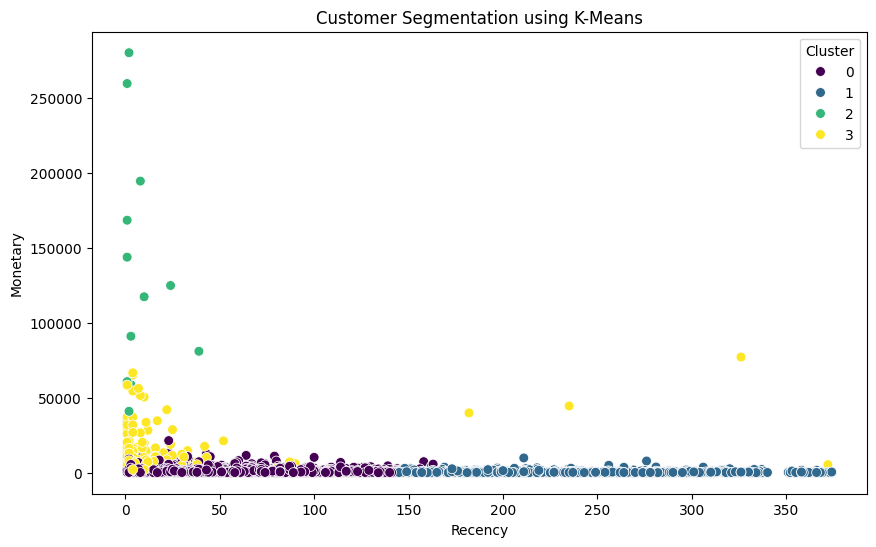

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='Recency',
    y='Monetary',
    hue='Cluster',
    data=rfm,
    palette='viridis',
    s=50
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency')
plt.ylabel('Monetary')
plt.show()

In [ ]:
# Calculate average RFM values for each cluster
cluster_analysis = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

print(cluster_analysis)

            Recency  Frequency       Monetary
Cluster                                      
0         43.702685   3.682711    1359.049284
1        248.075914   1.552015     480.617480
2          7.384615  82.538462  127338.313846
3         15.500000  22.333333   12709.090490


In [ ]:
def customer_segment(row):

    if row['Recency'] <= 30 and row['Frequency'] >= 10:
        return 'Loyal Customers'

    elif row['Monetary'] >= 3000:
        return 'High Value Customers'

    elif row['Recency'] > 90:
        return 'At Risk Customers'

    else:
        return 'Regular Customers'


rfm['CustomerSegment'] = rfm.apply(customer_segment, axis=1)

print(rfm[['Recency', 'Frequency', 'Monetary', 'Cluster', 'CustomerSegment']].head(10))

            Recency  Frequency  Monetary  Cluster       CustomerSegment
CustomerID                                                             
12346.0         326          1  77183.60        3  High Value Customers
12347.0           2          7   4310.00        0  High Value Customers
12348.0          75          4   1797.24        0     Regular Customers
12349.0          19          1   1757.55        0     Regular Customers
12350.0         310          1    334.40        1     At Risk Customers
12352.0          36          8   2506.04        0     Regular Customers
12353.0         204          1     89.00        1     At Risk Customers
12354.0         232          1   1079.40        1     At Risk Customers
12355.0         214          1    459.40        1     At Risk Customers
12356.0          23          3   2811.43        0     Regular Customers


In [ ]:
# Count customers in each segment

segment_count = rfm['CustomerSegment'].value_counts()

print("Customer Segmentation Summary:")
print(segment_count)

Customer Segmentation Summary:
CustomerSegment
Regular Customers       2303
At Risk Customers       1413
Loyal Customers          346
High Value Customers     276
Name: count, dtype: int64


In [ ]:
cluster_analysis = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

print(cluster_analysis)

            Recency  Frequency       Monetary
Cluster                                      
0         43.702685   3.682711    1359.049284
1        248.075914   1.552015     480.617480
2          7.384615  82.538462  127338.313846
3         15.500000  22.333333   12709.090490


In [ ]:
segment_count = rfm['CustomerSegment'].value_counts()

print("Customer Segmentation Summary:")
print(segment_count)


Customer Segmentation Summary:
CustomerSegment
Regular Customers       2303
At Risk Customers       1413
Loyal Customers          346
High Value Customers     276
Name: count, dtype: int64


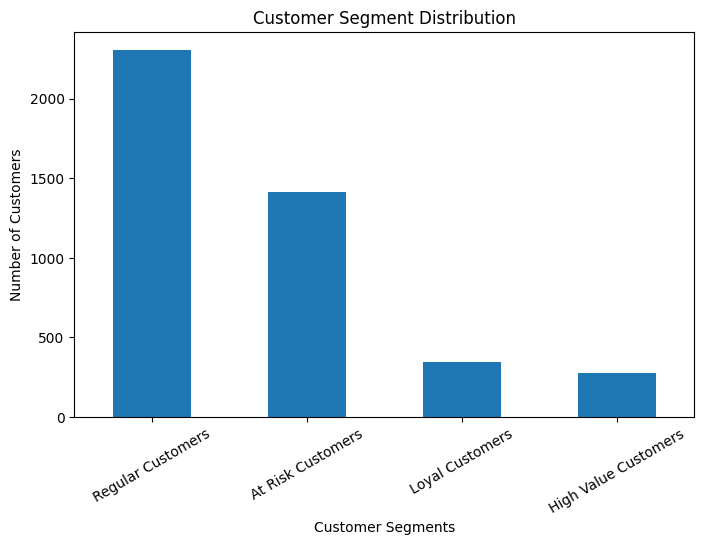

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

rfm['CustomerSegment'].value_counts().plot(kind='bar')

plt.title('Customer Segment Distribution')
plt.xlabel('Customer Segments')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.show()

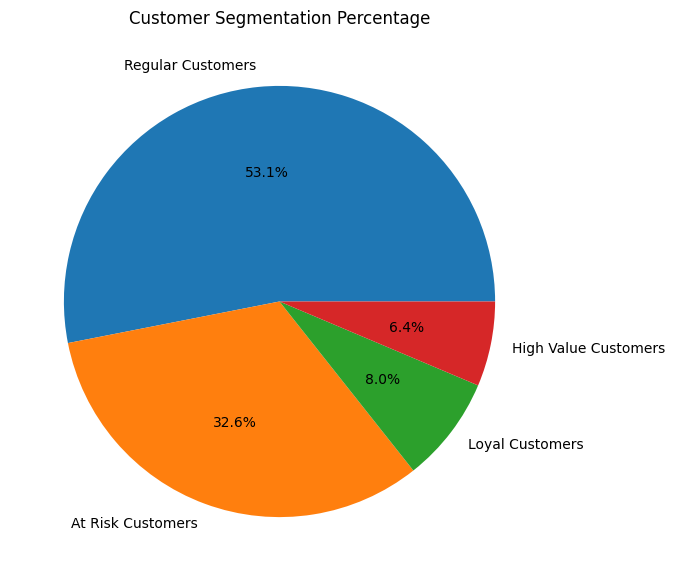

In [ ]:
plt.figure(figsize=(7,7))

rfm['CustomerSegment'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Customer Segmentation Percentage')
plt.ylabel('')
plt.show()

In [ ]:
rfm.to_csv('Customer_Segmentation_Result.csv')

print("Customer Segmentation Result Saved Successfully!")

Customer Segmentation Result Saved Successfully!


In [ ]:
from google.colab import files

files.download('Customer_Segmentation_Result.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>